# 1. Introduction

**Overview:**
- This project covers an analysis of episodes of the TV show The Simpsons, the longest running American animated TV series and longest running American sitcom. Debuting in 1989, it is currently in its 38th season as of 2026. This project involves aquiring data from two different sources: Wikipedia and IMDb. Wikipedia tables were used for the episode information, such as title, writer, director, etc., and the IMDb database was used to obtain the IMDb rating for each episode. This data was used to analyse the trajectory of the show over the course of its run and how it has changed over that time.

**Tools used:**
- Pandas
- Numpy
- Requests
- Datetime
- Matplotlib
- Seaborn

**Skills used:**
- Web scraping
- Data cleaning
- Exploratory data analyis
- Data visualisation

**Key questions:**
1. How does the viewership of The Simpsons episodes change over time?
2.  How do the IMDb ratings of The Simpsons episodes change over time?
3.  Which writers have the highest IMDb ratings/viewerships?
4.  Which directors have the highest IMDb ratings/viewerships?
5.  Do highly-rated episodes also have high viewing figures?

# 2. Data Loading

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import requests
import datetime as dt
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
import re
from io import StringIO

In [2]:
# Assign URLs
URL_1 = 'https://en.wikipedia.org/wiki/List_of_The_Simpsons_episodes_(seasons_1%E2%80%9320)'
URL_2 = 'https://en.wikipedia.org/wiki/List_of_The_Simpsons_episodes_(season_21%E2%80%93present)'

In [3]:
# Add User-Agent header for request
headers = {
    'User-Agent' : 'SimpsonsDataProject'
}

In [4]:
# Download webpages including User-Aget header
response_1 = requests.get(URL_1, headers = headers)
response_2 = requests.get(URL_2, headers = headers)

In [5]:
# Check if request succeeded
response_1.raise_for_status()
response_2.raise_for_status()

In [6]:
# Extract HTML tables into a list of DataFrames
episode_tables_1 = pd.read_html(StringIO(response_1.text))
episode_tables_2 = pd.read_html(StringIO(response_2.text))

In [7]:
# Verify loading
episode_tables_1[1].head()

,No. overall,No. in season,Title,Directed by,Written by,Original release date,Prod. code,U.S. viewers (millions)
0,1,1,"""Simpsons Roasting on an Open Fire""",David Silverman,Mimi Pond,"December 17, 1989[51]",7G08,26.7[52]
1,2,2,"""Bart the Genius""",David Silverman,Jon Vitti,"January 14, 1990[53]",7G02,24.5[52]
2,3,3,"""Homer's Odyssey""",Wes Archer,Jay Kogen & Wallace Wolodarsky,"January 21, 1990[54]",7G03,27.5[55]
3,4,4,"""There's No Disgrace Like Home""",Gregg Vanzo & Kent Butterworth,Al Jean & Mike Reiss,"January 28, 1990[56]",7G04,20.2[57]
4,5,5,"""Bart the General""",David Silverman,John Swartzwelder,"February 4, 1990[58]",7G05,27.1[59]


In [8]:
# Rename columns so that all tables contain consistent column titles
for i in range(2, 20):
    episode_tables_2[i] = episode_tables_2[i].rename(columns = {
        'Original release date [599]' : 'Original release date',
        'No. in season [a]' : 'No. in season',
        'Title [400]' : 'Title',
        'Original release date [400]' : 'Original release date',
    })

episode_tables_1[21] = episode_tables_1[21].rename(columns = {
    'Original release date [599]' : 'Original release date'
})

In [9]:
# Initialise episodes dataframe
episodes = pd.DataFrame()

In [10]:
# Assign data in tables to episodes dataframe and create a new column to distinguish between seasons
for i,season in enumerate(episode_tables_1[1:19] + episode_tables_1[20:22] + episode_tables_2[2:20], start = 1):
    season['Season'] = i
    episodes = pd.concat([episodes, season], ignore_index = True)

In [11]:
# Verify loading
episodes.head()

,No. overall,No. in season,Title,Directed by,Written by,Original release date,Prod. code,U.S. viewers (millions),Season
0,1.0,1.0,"""Simpsons Roasting on an Open Fire""",David Silverman,Mimi Pond,"December 17, 1989[51]",7G08,26.7[52],1
1,2.0,2.0,"""Bart the Genius""",David Silverman,Jon Vitti,"January 14, 1990[53]",7G02,24.5[52],1
2,3.0,3.0,"""Homer's Odyssey""",Wes Archer,Jay Kogen & Wallace Wolodarsky,"January 21, 1990[54]",7G03,27.5[55],1
3,4.0,4.0,"""There's No Disgrace Like Home""",Gregg Vanzo & Kent Butterworth,Al Jean & Mike Reiss,"January 28, 1990[56]",7G04,20.2[57],1
4,5.0,5.0,"""Bart the General""",David Silverman,John Swartzwelder,"February 4, 1990[58]",7G05,27.1[59],1


In [12]:
# Investigate dataframe size
episodes.shape

(881, 9)

---

In [13]:
# Import IMDb databases for episodes and ratings
imdb_episodes = pd.read_csv(
    'https://datasets.imdbws.com/title.episode.tsv.gz',
    sep='\t',
    compression='gzip',
    na_values='\\N'
)

imdb_ratings = pd.read_csv(
    'https://datasets.imdbws.com/title.ratings.tsv.gz',
    sep='\t',
    compression='gzip',
    na_values='\\N'
)

In [14]:
# Extract The Simpsons episodes from IMDb episodes database
simpsons_episodes = imdb_episodes[
    imdb_episodes['parentTconst'] == 'tt0096697'
].copy()

In [15]:
# Merge the ratings database with The Simpsons episodes table using IMDb episode code
simpsons_ratings = simpsons_episodes.merge(
    imdb_ratings,
    on='tconst',
    how='left'
)

In [16]:
# Verify loading
print(simpsons_ratings.head())

      tconst parentTconst  seasonNumber  episodeNumber  averageRating  \
0  tt0177842    tt0096697           7.0            6.0            8.7   
1  tt0348034    tt0096697           1.0            1.0            8.1   
2  tt0701040    tt0096697           5.0           10.0            8.6   
3  tt0701041    tt0096697           6.0           22.0            8.1   
4  tt0701042    tt0096697          14.0           16.0            7.1   

   numVotes  
0    4579.0  
1   10763.0  
2    4401.0  
3    3793.0  
4    1833.0  


# 3. Data Cleaning

In [17]:
# Investigate data types of columns
episodes.dtypes

No. overall                object
No. in season              object
Title                         str
Directed by                   str
Written by                    str
Original release date         str
Prod. code                    str
U.S. viewers (millions)       str
Season                      int64
dtype: object

In [18]:
# Remove annotations in No. overall column and convert to integer values
episodes['No. overall'] = pd.to_numeric(
    episodes['No. overall']
    .astype('string')
    .str.replace(r'\[.*?\]', '', regex = True)
).astype('Int64')

episodes['No. overall'].dtype

Int64Dtype()

In [19]:
# Replace '–' values with NaN and convert No.in season column to integer values
episodes['No. in season'] = pd.to_numeric(
    episodes['No. in season']
    .replace('–', np.nan, regex = True)
    ).astype('Int64')

episodes['No. in season'].dtype

Int64Dtype()

In [20]:
# Extract the first numerical value from the viewers column to account for HH values in earlier seasons
episodes['U.S. viewers (millions)'] =  (
    episodes['U.S. viewers (millions)']
    .str.extract(r'^(\d+\.?\d*)')[0]
)

In [21]:
# Convert viewers column into float datatype
episodes['U.S. viewers (millions)'] = pd.to_numeric(episodes['U.S. viewers (millions)'])
episodes['U.S. viewers (millions)'].dtype

dtype('float64')

In [22]:
# Remove the [] annotations and convert release date column to datetime datatype
episodes['Original release date'] = pd.to_datetime(
    episodes['Original release date']
    .str.replace(r'\[.*?\]', '', regex=True)
)

In [23]:
episodes.head()

,No. overall,No. in season,Title,Directed by,Written by,Original release date,Prod. code,U.S. viewers (millions),Season
0,1,1,"""Simpsons Roasting on an Open Fire""",David Silverman,Mimi Pond,1989-12-17,7G08,26.7,1
1,2,2,"""Bart the Genius""",David Silverman,Jon Vitti,1990-01-14,7G02,24.5,1
2,3,3,"""Homer's Odyssey""",Wes Archer,Jay Kogen & Wallace Wolodarsky,1990-01-21,7G03,27.5,1
3,4,4,"""There's No Disgrace Like Home""",Gregg Vanzo & Kent Butterworth,Al Jean & Mike Reiss,1990-01-28,7G04,20.2,1
4,5,5,"""Bart the General""",David Silverman,John Swartzwelder,1990-02-04,7G05,27.1,1


In [24]:
# Convert seasonNumber and episodeNumber to integer values
simpsons_ratings['seasonNumber'] = simpsons_ratings['seasonNumber'].astype('Int64')
simpsons_ratings['episodeNumber'] = simpsons_ratings['episodeNumber'].astype('Int64')

In [25]:
# Merge the simpsons_ratings table with the episodes dataframe using season and episode numbers
episodes = episodes.merge(
    simpsons_ratings[
        ['seasonNumber', 'episodeNumber', 'averageRating', 'numVotes']
        ],
    left_on = ['Season', 'No. in season'],
    right_on = ['seasonNumber', 'episodeNumber'],
    how = 'left'
)

In [26]:
# Find episodes that don't have IMDb ratings
print(
    "Episodes without IMDb ratings:",
    episodes['averageRating'].isna().sum()
)

Episodes without IMDb ratings: 39


In [27]:
# Check whether Season and seasonNumber column match
(episodes['Season'] == episodes['seasonNumber']).all()

np.True_

In [28]:
# Check whether No. in season and episodeNumber match
(episodes['No. in season'] == episodes['episodeNumber']).all()

np.True_

In [29]:
# Remove redundant columns
episodes = episodes.drop(columns = ['seasonNumber', 'episodeNumber'])

In [30]:
# Standardise column names
episodes = episodes.rename(columns = {
    'Season' : 'season_number',
    'No. overall' : 'episode_number_overall',
    'No. in season' : 'episode_number',
    'Title' : 'title',
    'Directed by' : 'director',
    'Written by' : 'writer',
    'Original release date' : 'release_date',
    'Prod. code' : 'production_code',
    'U.S. viewers (millions)' : 'us_viewers_millions',
    'averageRating' : 'average_rating',
    'numVotes' : 'num_votes'
})

In [31]:
# Convert num_votes column to intger datatype
episodes['num_votes'] = episodes['num_votes'].astype('Int64')

In [32]:
# Check dataframe
episodes.head()

,episode_number_overall,episode_number,title,director,writer,release_date,production_code,us_viewers_millions,season_number,average_rating,num_votes
0,1,1,"""Simpsons Roasting on an Open Fire""",David Silverman,Mimi Pond,1989-12-17,7G08,26.7,1,8.1,10763
1,2,2,"""Bart the Genius""",David Silverman,Jon Vitti,1990-01-14,7G02,24.5,1,7.6,7524
2,3,3,"""Homer's Odyssey""",Wes Archer,Jay Kogen & Wallace Wolodarsky,1990-01-21,7G03,27.5,1,7.3,6714
3,4,4,"""There's No Disgrace Like Home""",Gregg Vanzo & Kent Butterworth,Al Jean & Mike Reiss,1990-01-28,7G04,20.2,1,7.6,6492
4,5,5,"""Bart the General""",David Silverman,John Swartzwelder,1990-02-04,7G05,27.1,1,7.9,6692


In [33]:
# Check for missing values
episodes.isna().sum()

episode_number_overall    22
episode_number            30
title                     22
director                  22
writer                    22
release_date              22
production_code           22
us_viewers_millions       40
season_number              0
average_rating            39
num_votes                 39
dtype: int64

In [34]:
# Check for missing episodes
missing_check = episodes[
    episodes.isna().any(axis = 1)
    ]

missing_check.head()

,episode_number_overall,episode_number,title,director,writer,release_date,production_code,us_viewers_millions,season_number,average_rating,num_votes
18,<NA>,<NA>,NaN,NaN,NaN,NaT,NaN,NaN,2,NaN,<NA>
47,<NA>,<NA>,NaN,NaN,NaN,NaT,NaN,NaN,3,NaN,<NA>
72,<NA>,<NA>,NaN,NaN,NaN,NaT,NaN,NaN,4,NaN,<NA>
98,<NA>,<NA>,NaN,NaN,NaN,NaT,NaN,NaN,5,NaN,<NA>
124,<NA>,<NA>,NaN,NaN,NaN,NaT,NaN,NaN,6,NaN,<NA>


In [35]:
# Remove entries with missing titles
episodes = episodes.dropna(subset = ['title'])

In [36]:
# Replace TBA values in upcoming episodes
episodes = episodes.replace('TBA', np.nan)

In [37]:
# Investigate missing episode numbers
episodes[episodes['episode_number'].isna()]

,episode_number_overall,episode_number,title,director,writer,release_date,production_code,us_viewers_millions,season_number,average_rating,num_votes
832,778,<NA>,"""O C'mon All Ye Faithful""",Debbie Bruce Mahan,Carolyn Omine,2024-12-17,35ABF21,NaN,36,NaN,<NA>
833,779,<NA>,"""O C'mon All Ye Faithful""",Matthew Faughnan,Carolyn Omine,2024-12-17,35ABF22,NaN,36,NaN,<NA>
837,782,<NA>,"""The Past and the Furious""",Mike Frank Polcino,Rob LaZebnik,2025-02-12,35ABF19,NaN,36,NaN,<NA>
841,786,<NA>,"""Yellow Planet""",Timothy Bailey,J. Stewart Burns,2025-04-22,35ABF20,NaN,36,NaN,<NA>
861,806,<NA>,"""Extreme Makeover: Homer Edition""",Matthew Nastuk,Michael Price,2026-06-17,36ABF20,NaN,37,NaN,<NA>
862,807,<NA>,"""Extreme Makeover: Homer Edition""",Timothy Bailey,Nick Dahan,2026-06-17,36ABF21,NaN,37,NaN,<NA>
864,808,<NA>,"""Simpsley""",Debbie Bruce Mahan,Cesar Mazariegos,2026-07-03,36ABF19,NaN,37,NaN,<NA>
865,809,<NA>,"""Yellow Mirror""",Matthew Faughnan,Carolyn Omine & Kai Omine,2026-08-26,36ABF22,NaN,37,NaN,<NA>


In [38]:
# Check for any further annotations
for col in episodes.select_dtypes(include='str'):
    count = episodes[col].str.contains(r'\[.*?\]', na = False).sum()

    if count > 0:
        print(f'{col}: {count} annotations')

title: 7 annotations
director: 2 annotations
writer: 3 annotations
production_code: 3 annotations


In [39]:
cols = ['title', 'director', 'writer', 'production_code']

for col in cols:
    mask = episodes[col].str.contains(r'\[.*?\]', na = False)

    print(f'\n--- {col} ---')
    print(episodes.loc[mask, col])


--- title ---
874                           "Jersey Score"[420]
875                 "Don't Marge with Texas"[421]
876                                    "Bog"[422]
877                        "The Offendables"[423]
878    "Lock, Stock and One Stupid Narrator"[424]
879               "Billionaire on the Bayou"[425]
880                     "Lenny Goes Squiggy"[426]
Name: title, dtype: str

--- director ---
7      Rich Moore Kent Butterworth (uncredited)[64]
156                              David Silverman[a]
Name: director, dtype: str

--- writer ---
118     Jon Vitti[a]
156     Jon Vitti[b]
398    Dana Gould[b]
Name: writer, dtype: str

--- production_code ---
184    3F25[314] 3G01
187    3F27[319] 3G03
205    3F26[336] 3G02
Name: production_code, dtype: str


In [40]:
# Remove annotations
for col in cols:
    episodes[col] = (
        episodes[col]
        .str.replace(r'\[.*?\]', '', regex = True)
        .str.strip()
    )

In [41]:
# Define function to split up writing/directing credits
def split_credits(value):
    if pd.isna(value):
        return []

    # Remove writing-role labels
    value = re.sub(
        r'\*?(?:Story|Teleplay|Written)\s+by\*?\s*[:：]\s*',
        '',
        value,
        flags = re.IGNORECASE
    )

    # Remove remaining markdown formatting
    value = value.replace('*', '')

    # Split individual names
    names = re.split(r'\s*(?:,|&|\band\b|\n|\\)\s*', value)

    return [name.strip() for name in names if name.strip()]

In [42]:
# Split multiple writers into lists
episodes['writer'] = episodes['writer'].apply(split_credits)

In [43]:
# Split multiple directors into lists
episodes['director'] = episodes['director'].apply(split_credits)

In [44]:
episodes.head()

,episode_number_overall,episode_number,title,director,writer,release_date,production_code,us_viewers_millions,season_number,average_rating,num_votes
0,1,1,"""Simpsons Roasting on an Open Fire""",[David Silverman],[Mimi Pond],1989-12-17,7G08,26.7,1,8.1,10763
1,2,2,"""Bart the Genius""",[David Silverman],[Jon Vitti],1990-01-14,7G02,24.5,1,7.6,7524
2,3,3,"""Homer's Odyssey""",[Wes Archer],"[Jay Kogen, Wallace Wolodarsky]",1990-01-21,7G03,27.5,1,7.3,6714
3,4,4,"""There's No Disgrace Like Home""","[Gregg Vanzo, Kent Butterworth]","[Al Jean, Mike Reiss]",1990-01-28,7G04,20.2,1,7.6,6492
4,5,5,"""Bart the General""",[David Silverman],[John Swartzwelder],1990-02-04,7G05,27.1,1,7.9,6692


In [45]:
# Investigate repeated episode numbers
episodes[
    episodes.duplicated(
        subset = ['season_number', 'episode_number'],
        keep = False
    )
    ].sort_values(['season_number', 'episode_number']).head(10)

,episode_number_overall,episode_number,title,director,writer,release_date,production_code,us_viewers_millions,season_number,average_rating,num_votes
15,16,3,"""Treehouse of Horror""",[Wes Archer],[John Swartzwelder],1990-10-25,7F04,27.4,2,8.2,6619
16,16,3,"""Treehouse of Horror""",[Rich Moore],"[Jay Kogen, Wallace Wolodarsky]",1990-10-25,7F04,27.4,2,8.2,6619
17,16,3,"""Treehouse of Horror""",[David Silverman],"[Edgar Allan Poe, Sam Simon]",1990-10-25,7F04,27.4,2,8.2,6619
44,42,7,"""Treehouse of Horror II""",[Jim Reardon],"[Al Jean, Mike Reiss]",1991-10-31,8F02,20.0,3,8.2,5125
45,42,7,"""Treehouse of Horror II""",[Jim Reardon],"[Jeff Martin, George Meyer]",1991-10-31,8F02,20.0,3,8.2,5125
46,42,7,"""Treehouse of Horror II""",[Jim Reardon],"[Sam Simon, John Swartzwelder]",1991-10-31,8F02,20.0,3,8.2,5125
69,64,5,"""Treehouse of Horror III""",[Carlos Baeza],"[Al Jean, Mike Reiss]",1992-10-29,9F04,25.1,4,8.4,4914
70,64,5,"""Treehouse of Horror III""",[Carlos Baeza],"[Jay Kogen, Wallace Wolodarsky]",1992-10-29,9F04,25.1,4,8.4,4914
71,64,5,"""Treehouse of Horror III""",[Carlos Baeza],"[Sam Simon, Jon Vitti]",1992-10-29,9F04,25.1,4,8.4,4914
94,86,5,"""Treehouse of Horror IV""",[David Silverman],[Conan O'Brien (wraparounds)],1993-10-28,1F04,24.0,5,8.8,5205


# 4. Exploratory Data Analysis & Visualisations

## 4.0 Notable Episodes

In [46]:
# Find episode with highest number of U.S. viewers
episodes[['title', 'season_number', 'episode_number', 'release_date',
          'writer','director', 'average_rating', 'us_viewers_millions']][episodes['us_viewers_millions'] == episodes['us_viewers_millions'].max()]

,title,season_number,episode_number,release_date,writer,director,average_rating,us_viewers_millions
13,"""Bart Gets an 'F'""",2,1,1990-10-11,[David M. Stern],[David Silverman],8.3,33.6


In [47]:
# Find episode with highest IMDb rating
episodes[['title', 'season_number', 'episode_number', 'release_date',
          'writer','director', 'average_rating', 'us_viewers_millions']][episodes['average_rating'] == episodes['average_rating'].max()]

,title,season_number,episode_number,release_date,writer,director,average_rating,us_viewers_millions
197,"""Homer's Enemy""",8,23,1997-05-04,[John Swartzwelder],[Jim Reardon],9.3,11.8


In [48]:
# Find episode with lowest number of U.S. viewers
episodes[['title', 'season_number', 'episode_number', 'release_date',
          'writer','director', 'average_rating', 'us_viewers_millions']][episodes['us_viewers_millions'] == episodes['us_viewers_millions'].min()]

,title,season_number,episode_number,release_date,writer,director,average_rating,us_viewers_millions
845,"""Estranger Things""",36,18,2025-05-18,[Tim Long],[Matthew Nastuk],6.4,0.54


In [49]:
# Find episode with lowest IMDb rating
episodes[['title', 'season_number', 'episode_number', 'release_date',
          'writer','director', 'average_rating', 'us_viewers_millions']][episodes['average_rating'] == episodes['average_rating'].min()]

,title,season_number,episode_number,release_date,writer,director,average_rating,us_viewers_millions
559,"""Lisa Goes Gaga""",23,22,2012-05-20,[Tim Long],[Matthew Schofield],4.0,4.82


## 4.1 Viewership Trends

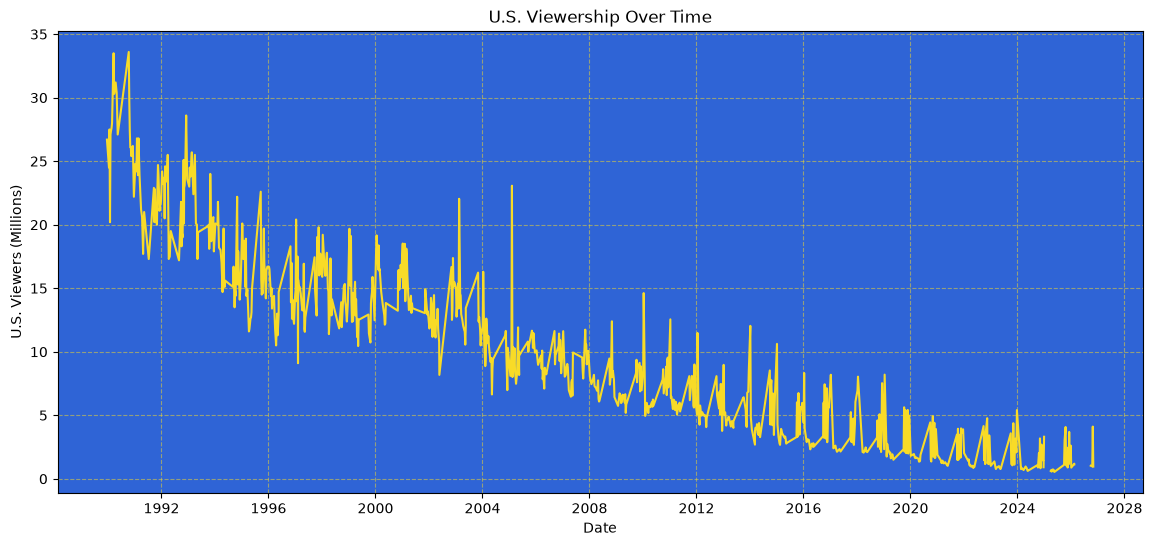

In [50]:
# Plot a graph of U.S. viewership over time
plt.figure (figsize = (14, 6))

plt.plot(
    episodes['release_date'],
    episodes['us_viewers_millions'],
    color = '#f8db27'
)

plt.title('U.S. Viewership Over Time')
plt.xlabel('Date')
plt.ylabel('U.S. Viewers (Millions)')
plt.grid(linestyle = '--', alpha = 0.5, color = '#f8db27')

ax = plt.gca()
ax.set_facecolor('#2f64d6')

plt.show()

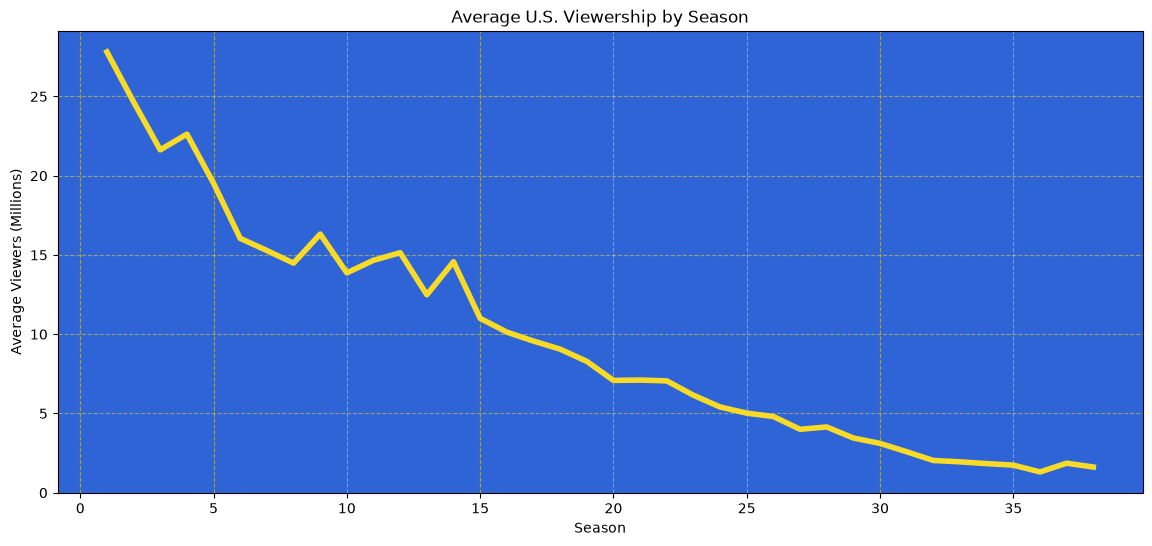

In [51]:
# Find mean viewership for each season
season_viewership = (
    episodes.groupby('season_number')['us_viewers_millions'].mean()
)

# Plot mean viewership by season
plt.figure(figsize = (14, 6))

plt.plot(season_viewership, color = '#f8db27', linewidth = 4)

plt.title("Average U.S. Viewership by Season")
plt.xlabel("Season")
plt.ylabel("Average Viewers (Millions)")
plt.grid(linestyle = '--', alpha = 0.5, color = '#f8db27')

ax = plt.gca()
ax.set_facecolor('#2f64d6')

plt.show()

In [52]:
# Create heatmap data
viewers_heatmap_data = episodes.pivot_table(
    index = 'episode_number',
    columns = 'season_number',
    values = 'us_viewers_millions',
    aggfunc = 'mean'
)

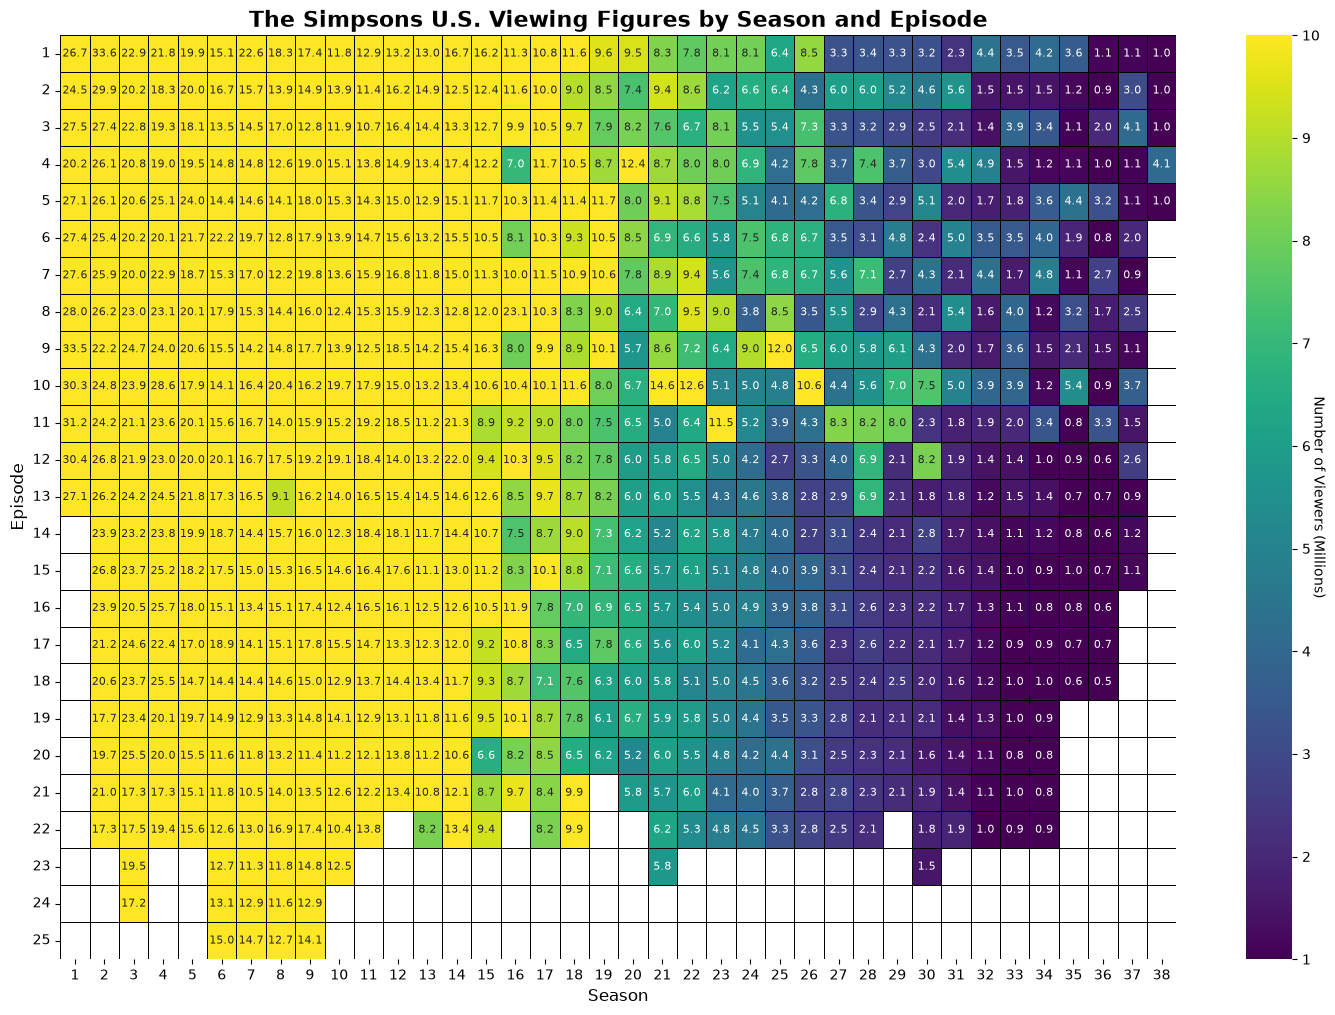

In [53]:
# Plot heatmap
plt.figure(figsize = (18, 12))

ax = sns.heatmap(
    viewers_heatmap_data,
    cmap = 'viridis',
    vmin = 1,
    vmax = 10,
    linewidths = 0.5,
    linecolor = 'black',
    annot = True,
    annot_kws = {'size' : 8},
    fmt = '.1f'
)

ax.collections[0].colorbar.set_label(
    'Number of Viewers (Millions)',
    rotation=270
)

plt.xlabel('Season', fontsize = 12)
plt.ylabel('Episode', fontsize = 12)
plt.yticks(rotation = 0)
plt.title('The Simpsons U.S. Viewing Figures by Season and Episode', fontsize = 16, fontweight = 'bold')

plt.show()

## 4.2 IMDb Rating Trends

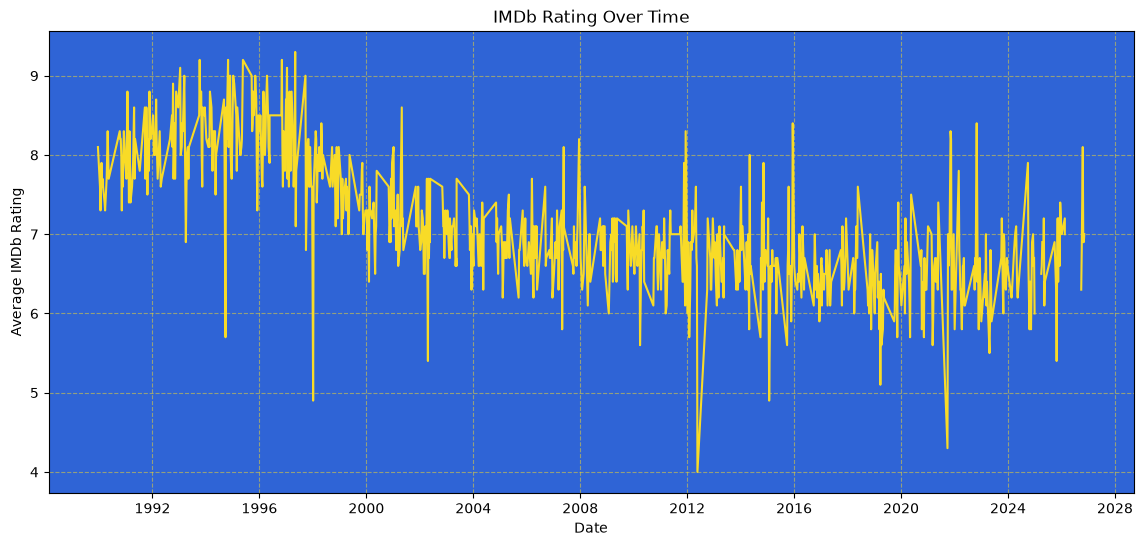

In [54]:
# Plot a graph of IMDb rating over time
plt.figure (figsize = (14, 6))

plt.plot(
    episodes['release_date'],
    episodes['average_rating'],
    color = '#f8db27'
)

plt.title('IMDb Rating Over Time')
plt.xlabel('Date')
plt.ylabel('Average IMDb Rating')
plt.grid(linestyle = '--', alpha = 0.5, color = '#f8db27')

ax = plt.gca()
ax.set_facecolor('#2f64d6')

plt.show()

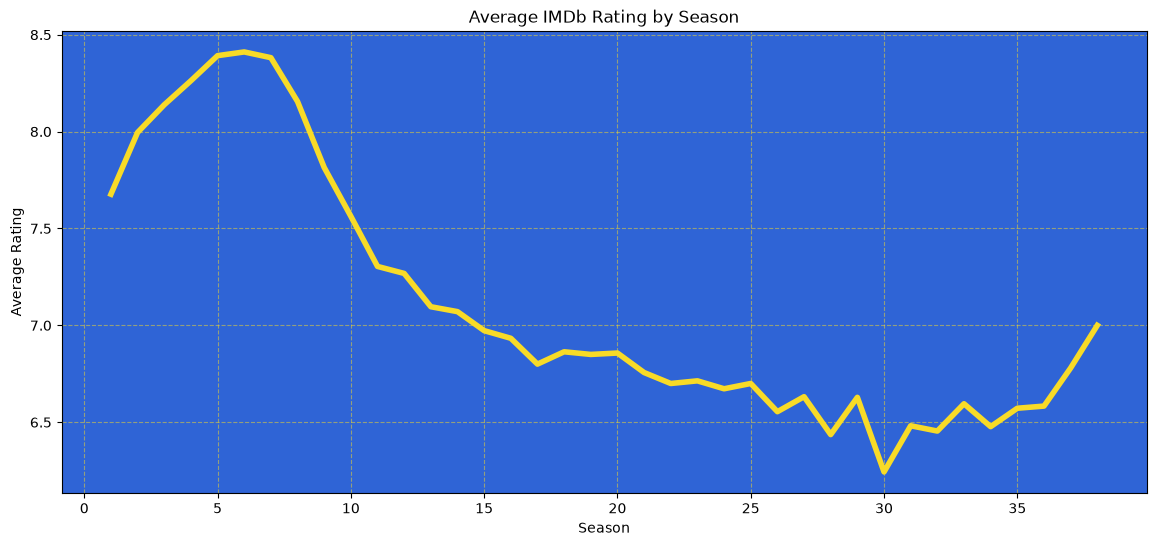

In [55]:
# Find mean IMDb rating for each season
season_rating = (
    episodes.groupby('season_number')['average_rating'].mean()
)

# Plot mean IMDb rating by season
plt.figure(figsize = (14, 6))

plt.plot(season_rating, color = '#f8db27', linewidth = 4)

plt.title("Average IMDb Rating by Season")
plt.xlabel("Season")
plt.ylabel("Average Rating")
plt.grid(linestyle = '--', alpha = 0.5, color = '#f8db27')

ax = plt.gca()
ax.set_facecolor('#2f64d6')

plt.show()

In [56]:
# Create heatmap data
rating_heatmap_data = episodes.pivot_table(
    index = 'episode_number',
    columns = 'season_number',
    values = 'average_rating',
    aggfunc = 'mean'
)

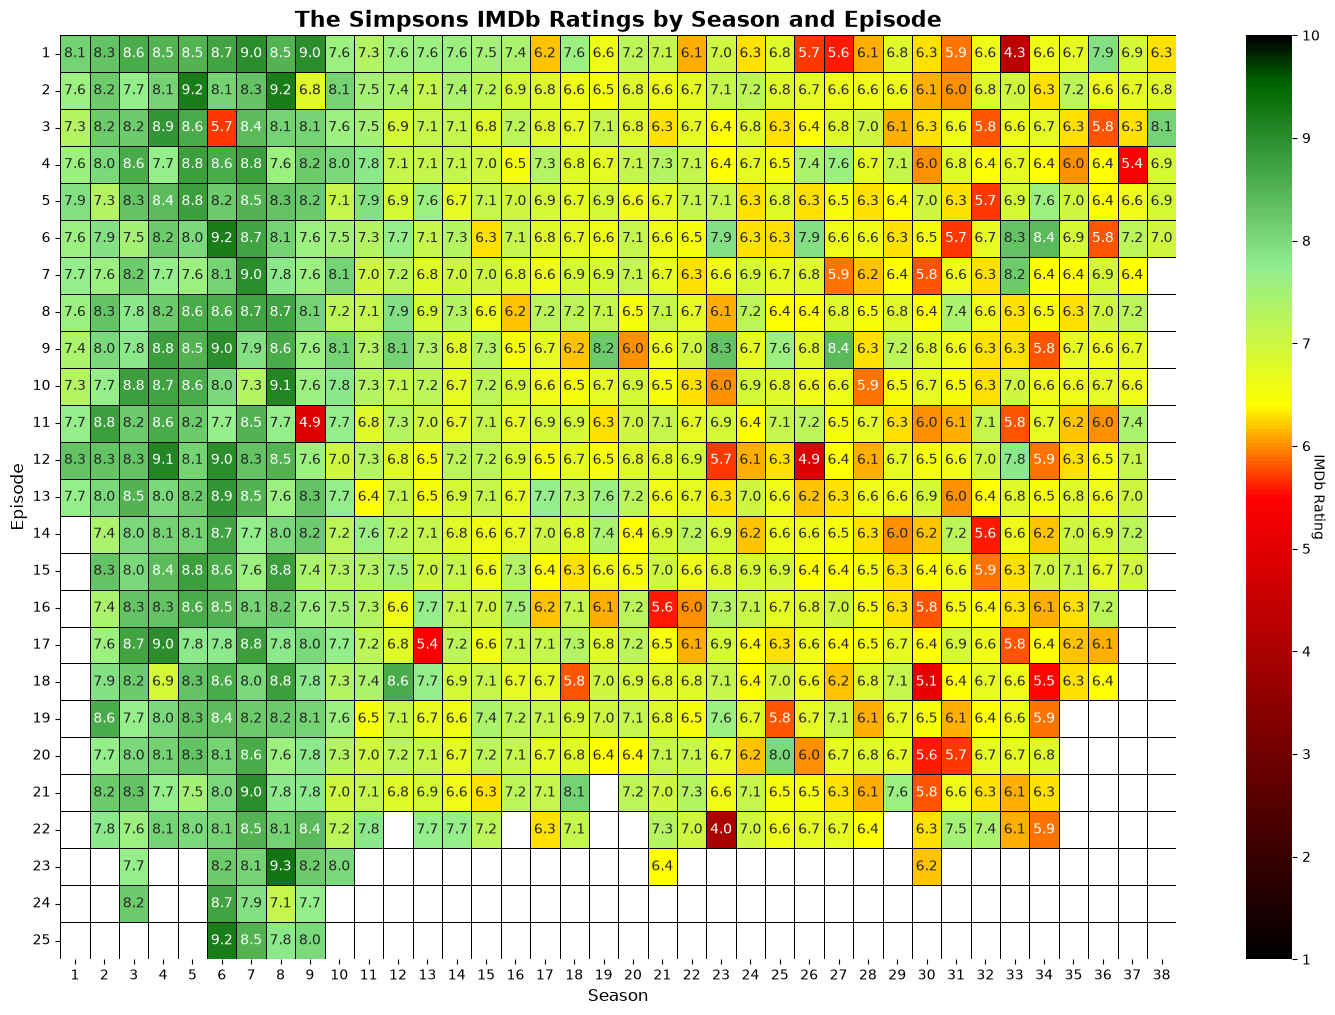

In [57]:
# Create colourmap
colours = [
    (0, 'black'),
    (0.5, 'red'),
    (0.6, 'yellow'),
    (0.75, 'lightgreen'),
    (0.95, 'darkgreen'),
    (1, 'black')
]

custom_cmap = LinearSegmentedColormap.from_list(
    'average_rating',
    colours
)

# Plot heatmap
plt.figure(figsize = (18, 12))

ax = sns.heatmap(
    rating_heatmap_data,
    cmap = custom_cmap,
    vmin = 1,
    vmax = 10,
    linewidths = 0.5,
    linecolor = 'black',
    annot = True,
    annot_kws = {'size' : 10},
    fmt = '.1f'
)

ax.collections[0].colorbar.set_label(
    'IMDb Rating',
    rotation=270
)

plt.xlabel('Season', fontsize = 12)
plt.ylabel('Episode', fontsize = 12)
plt.yticks(rotation = 0)
plt.title('The Simpsons IMDb Ratings by Season and Episode', fontsize = 16, fontweight = 'bold')

plt.show()

## 4.3 Top Writers

In [58]:
# Create individual entries for each writer for episodes with multiple writers
writers = episodes.copy()
writers = writers.explode('writer')
writers['writer'] = writers['writer'].str.strip()

In [59]:
# Calculate number of episodes written and average rating for each writer
writer_stats = (
    writers.groupby('writer')
    .agg(
        episodes_written = ('episode_number_overall', 'nunique'),
        average_rating = ('average_rating', 'mean'),
    )
    .sort_values('episodes_written', ascending=False)
)

writer_stats.head()

,episodes_written,average_rating
writer,,
John Swartzwelder,58,7.893103
John Frink,39,6.766667
Joel H. Cohen,38,6.710526
Tim Long,36,6.569444
Carolyn Omine,30,6.940741


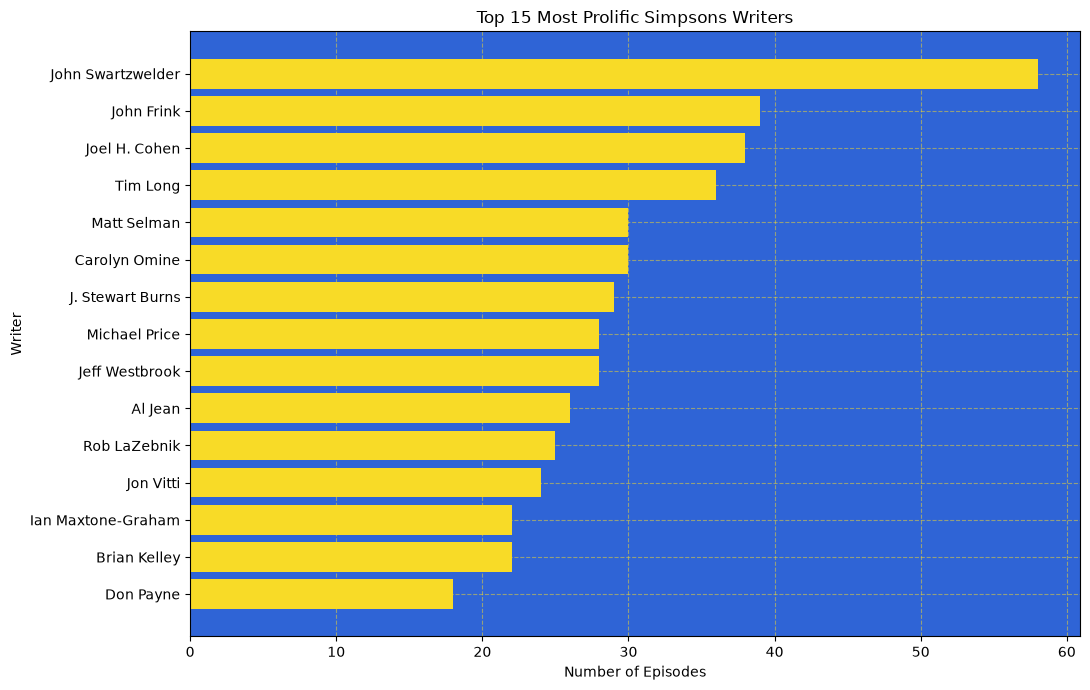

In [60]:
# Find top 15 most prolific writers
top_writers = writer_stats.head(15).sort_values('episodes_written')

# Plot top 15 most prolific writers
plt.figure(figsize = (11, 7))

plt.barh(
    top_writers.index,
    top_writers['episodes_written'],
    color = '#f8db27'
)

plt.title('Top 15 Most Prolific Simpsons Writers')
plt.xlabel('Number of Episodes')
plt.ylabel('Writer')
plt.grid(linestyle = '--', alpha = 0.5, color = '#f8db27')

ax = plt.gca()
ax.set_facecolor('#2f64d6')

plt.tight_layout()
plt.show()

In [61]:
# Calculate the writers with the highest average IMDb rating
top_rated_writers = (
    writer_stats[writer_stats['episodes_written'] >=5]
    .sort_values('average_rating', ascending = False)
    .head(15)
)

top_rated_writers

,episodes_written,average_rating
writer,,
Greg Daniels,8,8.675000
Josh Weinstein,13,8.353846
Bill Oakley,13,8.353846
Jonathan Collier,6,8.333333
Jennifer Crittenden,5,8.260000
David X. Cohen,13,8.215385
Ken Keeler,6,8.200000
Richard Appel,7,8.157143
Jay Kogen,10,8.030000


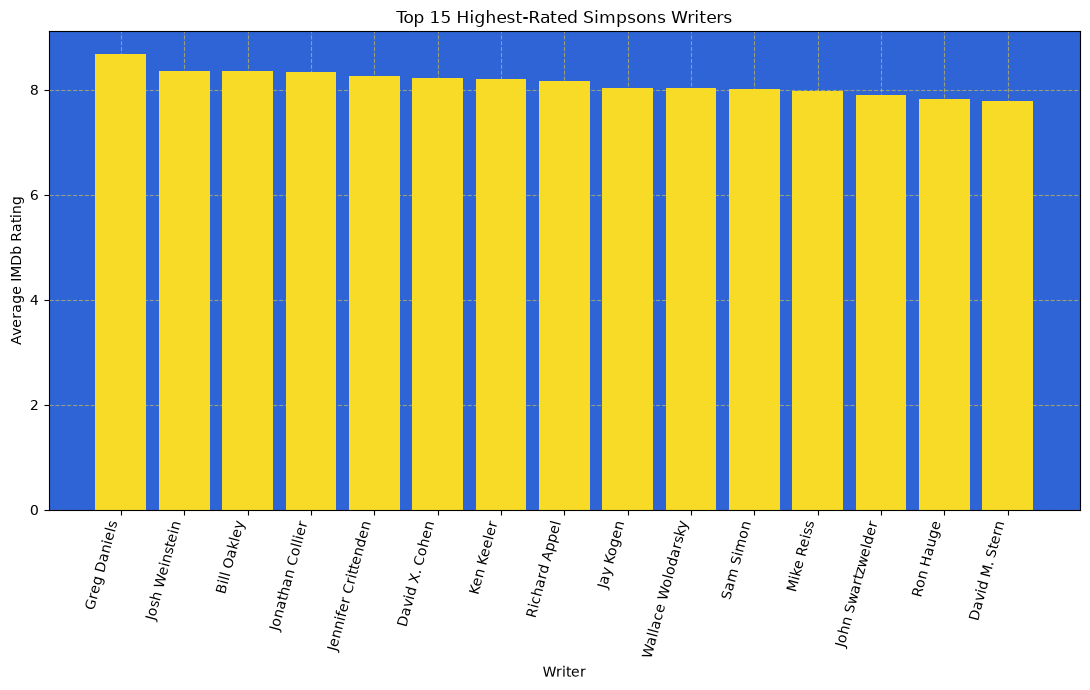

In [62]:
# Plot top 15 highest-rated Simpsons writers
plt.figure(figsize = (11, 7))

plt.bar(
    top_rated_writers.index,
    top_rated_writers['average_rating'],
    color = '#f8db27'
)

plt.title('Top 15 Highest-Rated Simpsons Writers')
plt.xlabel('Writer')
plt.ylabel('Average IMDb Rating')
plt.xticks(rotation = 75, ha ='right')
plt.grid(linestyle = '--', alpha = 0.5, color = '#f8db27')

ax = plt.gca()
ax.set_facecolor('#2f64d6')

plt.tight_layout()
plt.show()

## 4.4 Top Directors

In [63]:
# Create individual entries for each director for episodes with multiple directors
directors = episodes.copy()
directors = directors.explode('director')
directors['director'] = directors['director'].str.strip()

In [64]:
# Calculate number of episodes directed and average rating for each director
director_stats = (
    directors.groupby('director')
    .agg(
        episodes_directed = ('episode_number_overall', 'nunique'),
        average_rating = ('average_rating', 'mean'),
    )
    .sort_values('episodes_directed', ascending=False)
)

director_stats.head()

,episodes_directed,average_rating
director,,
Steven Dean Moore,87,6.921348
Mark Kirkland,84,7.311628
Matthew Nastuk,68,6.688406
Bob Anderson,66,6.977143
Mike Frank Polcino,45,6.565909


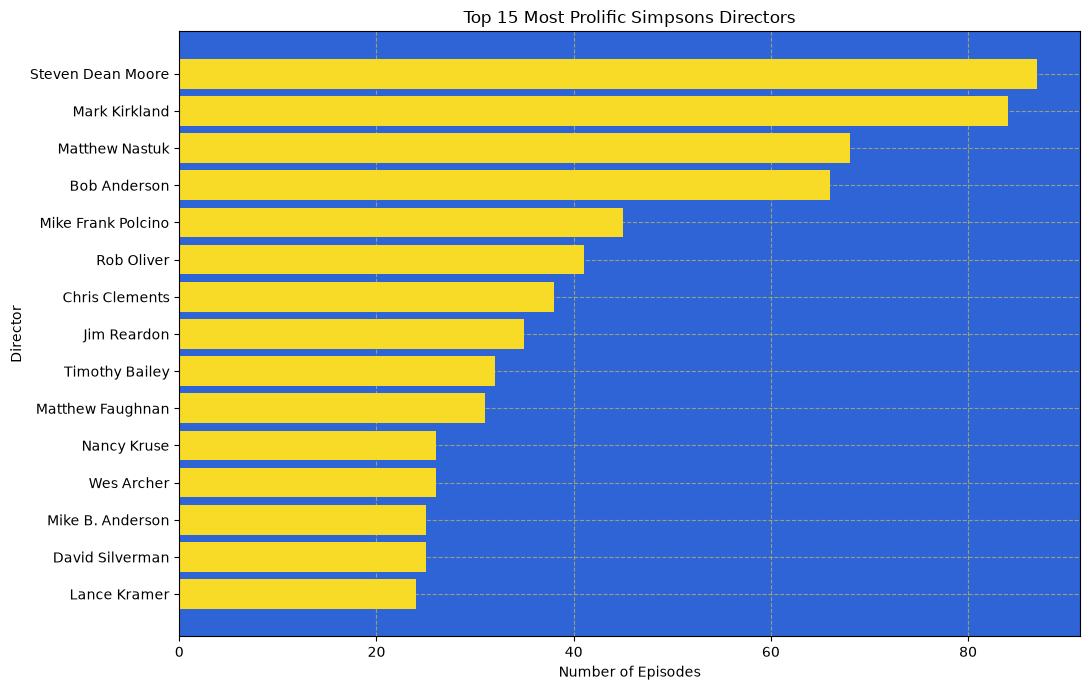

In [65]:
#Calculate top 15 most prolific directors
top_directors = director_stats.head(15).sort_values('episodes_directed')

# plot top 15 most prolific directors
plt.figure(figsize = (11, 7))

plt.barh(
    top_directors.index,
    top_directors['episodes_directed'],
    color = '#f8db27'
)

plt.title('Top 15 Most Prolific Simpsons Directors')
plt.xlabel('Number of Episodes')
plt.ylabel('Director')
plt.grid(linestyle = '--', alpha = 0.5, color = '#f8db27')

ax = plt.gca()
ax.set_facecolor('#2f64d6')

plt.tight_layout()
plt.show()

In [66]:
# Calculate the directors with the highest average IMDb rating
top_rated_directors = (
    director_stats[director_stats['episodes_directed'] >=5]
    .sort_values('average_rating', ascending = False)
    .head(15)
)

top_rated_directors

,episodes_directed,average_rating
director,,
Rich Moore,16,8.312500
Jeffrey Lynch,12,8.300000
Jim Reardon,35,8.241463
Wes Archer,26,8.184615
Carlos Baeza,9,8.181818
Swinton O. Scott III,7,8.100000
Susie Dietter,11,8.009091
David Silverman,25,7.826667
Dominic Polcino,7,7.814286


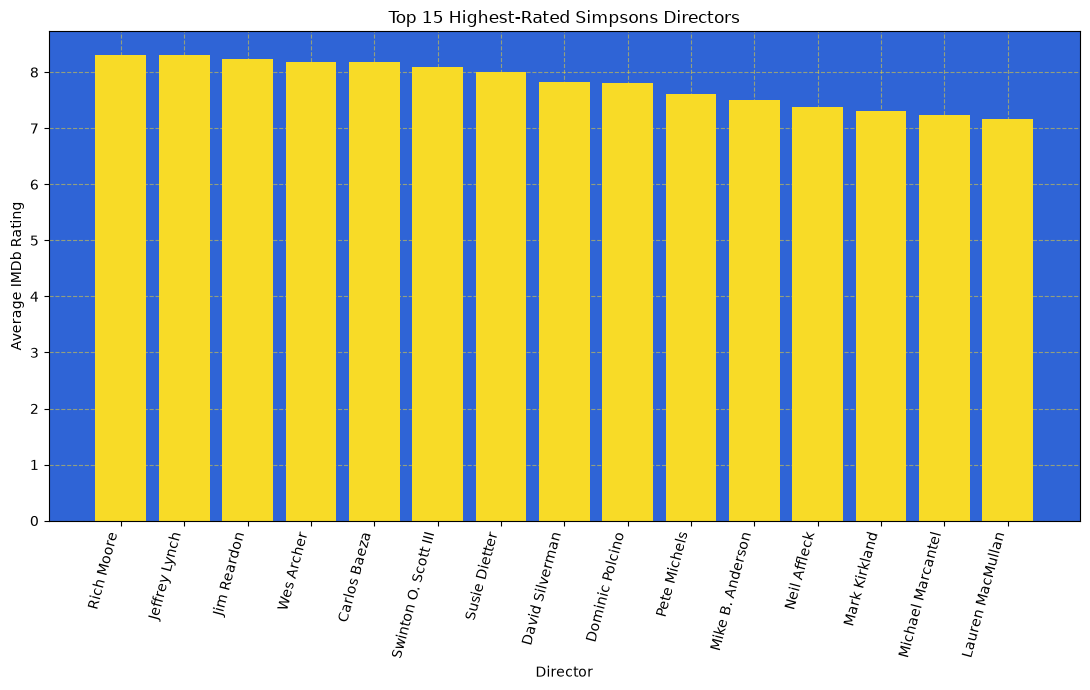

In [67]:
# Plot top 15 highest-rated Simpsons directors
plt.figure(figsize = (11, 7))

plt.bar(
    top_rated_directors.index,
    top_rated_directors['average_rating'],
    color = '#f8db27'
)

plt.title('Top 15 Highest-Rated Simpsons Directors')
plt.xlabel('Director')
plt.ylabel('Average IMDb Rating')
plt.xticks(rotation = 75, ha = 'right')
plt.grid(linestyle = '--', alpha = 0.5, color = '#f8db27')

ax = plt.gca()
ax.set_facecolor('#2f64d6')

plt.tight_layout()
plt.show()

# 5. Key Findings

1. The viewership of The Simpsons has consistently declined over its run. There have been peaks in  viewership within seasons, but the average viewership has largely decreased with later seasons.
2. The way the IMDb rating of The Simpsons has changed over time is a bit more complicated. The show's average IMDb rating initially increased for its first six seasons, before it began to steadily decline. During the "Golden Age" of seasons 3-8 each season's average IMDb rating never dropped below 8.0, though there are still low-rated episodes in this range, notably season 6's "Another Simpsons Clip Show". The value of this rating mostly decreased, reaching its lowest point at season 30 whereafter a small uptick in rating occurred.
3. John Swartzwelder is the most prolific Simpsons writer by some way, having written 58 episodes over the show's run with an average IMDb rating of 7.9. The writer with the highest average IMDb rating is Greg Daniels, with an average rating of 8.7, though only 8 episodes have been written by him.
4. Steven Dean Moore is the most prolific Simpsons director, having directed 87 episodes in total, followed by Mark Kirkland, who directed 84. The highest-rated director on average was Rich Moore, with an average score of 8.3 for his episodes.

# 6. Conclusion

The project explored the relationship between episode ratings, seasons, writers, and directors throughout the history of The Simpsons. The analysis revealed several interesting patterns.

It is important to recognise that IMDb ratings are based on user-submitted opinions and should not necessarily be considered an objective measure of episode quality. Additionally, limitations in the availability and consistency of the original data may have influenced some aspects of the analysis.